# 06 — Where this stops working

Every result so far says demand-responsive routing beats a fixed route. This
notebook looks for the conditions under which that is **false**, and finds
them.

That is deliberate. "Insertion routing beats a fixed timetable" is a weak
claim, because it is unfalsifiable as stated — it depends entirely on the
operating point. **"It beats a fixed timetable below roughly 60% seat
occupancy, and loses above it"** is a much stronger one, because both halves
are measured.

The experiment: raise the demand rate step by step, at two bus capacities,
under two passenger regimes, and watch for the crossing.

Runtime: about ten minutes at `"quick"`; **an hour or more at `"full"`**, and
the patient high-load cells are the slow ones — a bus that nobody gives up on
accumulates a very long schedule.

In [1]:
# --- Bootstrap ------------------------------------------------------------
# This notebook imports the project as `src.…`, which requires the repository
# root on the import path. `./jupyter-run.sh` puts it there; opening the file
# any other way does not. This cell finds the root by walking up from the
# working directory, so the notebook runs wherever it is launched from and
# whatever folder it sits in.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Seeded runs only reproduce when Python's string hashing is pinned: several
# policies break ties with min() over a set, whose iteration order is
# randomised per process otherwise. The simulation refuses to run unpinned;
# this says so now rather than after a long cell.
if os.environ.get("PYTHONHASHSEED") in (None, "random"):
    print("WARNING: PYTHONHASHSEED is not pinned, so seeded runs will be "
          "refused.\n         Launch with ./jupyter-run.sh, or set "
          "PYTHONHASHSEED=0.")

print(f"repository root: {ROOT}")

repository root: /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus


In [2]:
import os

# How much work this notebook does. Every notebook in this folder has this
# switch and honours the AUTOBUS_SCALE environment variable, so nothing here
# needs editing to run it bigger or smaller.
#
#   "quick"  the default: minutes, same conclusions, wider error bars
#   "full"   the sample sizes behind the figures in the submitted documents
#   "smoke"  a tiny end-to-end check that the notebook runs at all
#
# The outputs saved in this file were produced at "full".
SCALE = os.environ.get("AUTOBUS_SCALE", "quick")
print(f"running at SCALE = {SCALE!r}")

running at SCALE = 'quick'


In [3]:
import matplotlib.pyplot as plt
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

In [4]:
# The campus map: the world behind every synthetic result in this project.
# stop_density=0.5 is load-bearing -- the generator's default of 0.15 gives a
# 6-stop map on this seed, on which every policy ties. See notebook 01.
CAMPUS = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
              stop_density=0.5)

## The design

One variable at a time, and everything else pinned:

| Axis | Values | Why |
|---|---|---|
| Offered demand | a ladder of arrival intervals | The thing being varied |
| Bus capacity | 40 and 20 seats | 40 = seats never bind; 20 = they do |
| Regime | impatient (900 s patience) and patient (no give-up) | Abandonment caps the queue; without it, overload is visible |
| Policy | fixed route, skip-stop, and insertion at two windows | Rigid against clever |

The capacity pair is the key to the design. **Capacity is not really the
variable — occupancy is.** Halving the seats at the same demand doubles the
fraction of the bus that is full, which is the quantity that actually decides
the outcome. Running both capacities is what lets the result be stated in
occupancy rather than in requests per minute, and occupancy is what transfers
to another map.

In [5]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import DEFAULT_RUNS_DIR, load_frame
from src.map.graph import PlanarStreetGraph

RUNS = Path(os.environ.get("AUTOBUS_RUNS_DIR", DEFAULT_RUNS_DIR))

POLICIES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Skip-stop", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Window W900", lambda g: WindowInsertionPolicy(g, max_wait_s=900.0)),
    ("Reordering W1800",
     lambda g: ReorderingInsertionPolicy(g, max_wait_s=1800.0)),
]

# Arrival intervals in seconds; shorter interval = heavier load.
INTERVALS = {
    "smoke": [60.0, 30.0],
    "quick": [60.0, 45.0, 30.0],
    "full": [60.0, 45.0, 40.0, 35.0, 30.0, 25.0, 20.0],
}[SCALE]

CAPACITIES = [40, 20]
SEEDS = {"smoke": range(2), "quick": range(8), "full": range(30)}[SCALE]
REQUESTS = {"smoke": 60, "quick": 250, "full": 600}[SCALE]

# The patient regime has no abandonment, so a run only ends when the last
# passenger is delivered. The ceiling has to be generous or the slowest cells
# get truncated -- and a truncated run reports a wait time that is a fact
# about the ceiling rather than about the policy.
MAX_TIME = 250_000.0

REGIMES = {"impatient": 900.0, "patient": None}
N_JOBS = 1 if SCALE == "smoke" else -1

total = (len(INTERVALS) * len(CAPACITIES) * len(POLICIES)
         * len(list(SEEDS)) * len(REGIMES))
print(f"{total} runs")
print(f"offered demand: "
      f"{', '.join(f'{60 / i:.2f}' for i in INTERVALS)} requests/min")

384 runs
offered demand: 1.00, 1.33, 2.00 requests/min


In [6]:
def world_for(capacity, patience):
    """
    Describe this cell's world for the run identity.

    Capacity and patience are trial settings rather than world settings, but
    the regime name is recorded here so the two ladders never pool.
    :param capacity: Seats on the bus.
    :param patience: Seconds before a passenger gives up, or None.
    :return: The world identity.
    """
    return {"map": "planar", "n_seeds": CAMPUS["n_seeds"],
            "bounds": list(CAMPUS["bounds"]), "map_seed": CAMPUS["seed"],
            "stop_density": CAMPUS["stop_density"], "backend": "MockBackend",
            "regime": "patient" if patience is None else "impatient"}


from tqdm.auto import tqdm

graph = PlanarStreetGraph.generate(**CAMPUS)

# Four levels of bar, because this is the longest cell in the folder and a
# silent hour is indistinguishable from a hung one: regime, then capacity,
# then demand rate, then run_campaign's own bar over that cell's runs.
for regime, patience in tqdm(REGIMES.items(), total=len(REGIMES),
                             desc="regimes", unit="regime"):
    for capacity in tqdm(CAPACITIES, desc=f"  {regime}", unit="capacity",
                         leave=False):
        for interval in tqdm(INTERVALS, desc=f"    capacity {capacity}",
                             unit="rate", leave=False):
            outcome = run_campaign(
                policies=POLICIES,
                seeds=SEEDS,
                world=world_for(capacity, patience),
                graph=graph,
                directory=RUNS,
                n_jobs=N_JOBS,
                progress=True,
                max_requests=REQUESTS,
                demand_interval_s=interval,
                capacity=capacity,
                max_wait_s=patience,
                max_time=MAX_TIME,
            )
            tqdm.write(f"{regime:<10} cap {capacity:>2}  "
                       f"{60 / interval:.2f}/min  ->  "
                       f"{outcome.ran} run, {outcome.skipped} cached")

regimes:   0%|          | 0/2 [00:00<?, ?regime/s]

  impatient:   0%|          | 0/2 [00:00<?, ?capacity/s]

    capacity 40:   0%|          | 0/3 [00:00<?, ?rate/s]

campaign:   0%|          | 0/32 [00:00<?, ?it/s]

impatient  cap 40  1.00/min  ->  32 run, 0 cached


campaign:   0%|          | 0/32 [00:00<?, ?it/s]

... (21 outputs left out)

campaign:   0%|          | 0/32 [00:00<?, ?it/s]

patient    cap 20  1.33/min  ->  32 run, 0 cached


campaign:   0%|          | 0/32 [00:00<?, ?it/s]

patient    cap 20  2.00/min  ->  32 run, 0 cached


In [7]:
frame = load_frame(RUNS)
frame = frame[
    (frame["identity.trial.max_requests"] == REQUESTS)
    & (frame["identity.trial.demand_interval_s"].isin(INTERVALS))
    & (frame["identity.trial.capacity"].isin(CAPACITIES))
    & (frame["identity.world.map_seed"] == CAMPUS["seed"])
].copy()
frame["offered"] = 60 / frame["identity.trial.demand_interval_s"]
frame["regime"] = frame["identity.world.regime"]
frame["capacity"] = frame["identity.trial.capacity"]
frame["policy"] = frame["identity.policy"]
print(f"{len(frame)} runs collected")

384 runs collected


## 1. Is the bus actually saturated?

Before reading any comparison, check that the ladder reached the regime it was
built to test. Occupancy is estimated by Little's law — the average number of
passengers aboard is the arrival rate times the average ride time — as a
fraction of the seats.

**Report it per policy, not for the busiest arm.** A guard that quotes
whichever policy is fullest can report 73% while the policy actually under
test is at 50%, and the experiment then does not test what it claims to.

In [8]:
frame["occupancy"] = (
    frame["kpi.throughput"] / 60 * frame["kpi.mean_ride_time"]
    / frame["capacity"])

occupancy = (frame[frame["regime"] == "patient"]
             .groupby(["capacity", "offered", "policy"])["occupancy"]
             .mean().unstack() * 100).round(1)
display(occupancy)

reached = occupancy.max().max()
print(f"\npeak occupancy reached by any arm: {reached:.0f}%")
print("the threshold under test is ~60%",
      "-- REACHED" if reached > 60 else "-- NOT reached; add rungs")

policy             Fixed route  Reordering W1800  Skip-stop  Window W900
capacity offered                                                        
20       1.000000         49.2              29.2       47.9         41.3
         1.333333         62.3              42.1       61.8         64.1
         2.000000         74.6              66.6       75.7         79.5
40       1.000000         24.6              14.6       24.0         20.7
         1.333333         31.6              21.1       31.3         29.8
         2.000000         43.8              31.5       44.1         42.8


peak occupancy reached by any arm: 80%
the threshold under test is ~60% -- REACHED


## 2. The crossover

For each demand rate, how much better (or worse) the clever policy is than the
plain fixed route, in seconds of mean wait, **compared seed by seed**.

Positive means routing is winning. The moment the line crosses zero is the
scope condition.

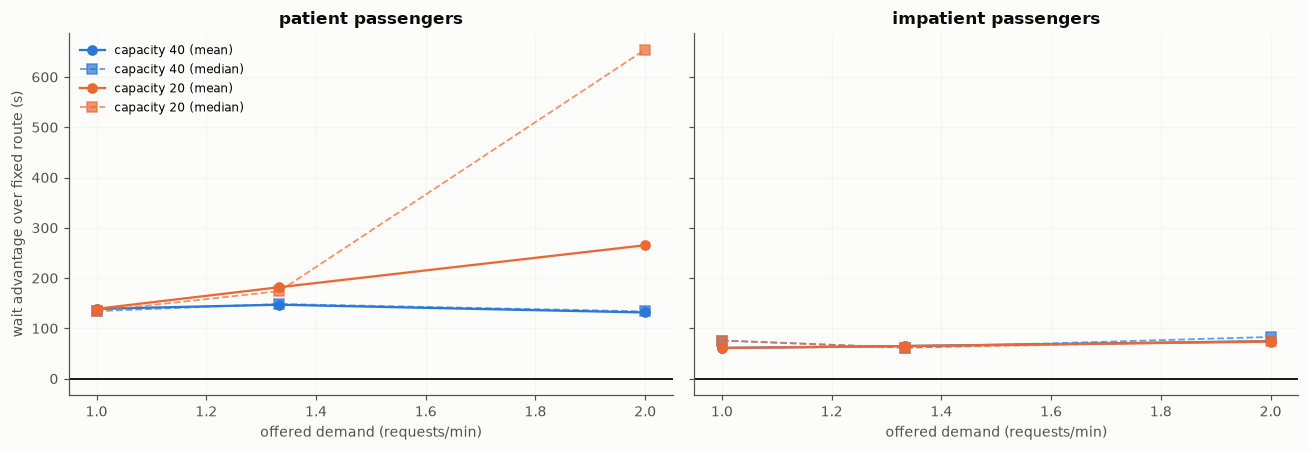

In [9]:
def gap_against_fixed(regime, capacity, policy="Reordering W1800"):
    """
    Per-seed wait advantage of one policy over the fixed route.
    :param regime: "patient" or "impatient".
    :param capacity: Seats on the bus.
    :param policy: The policy under test.
    :return: One row per (offered demand, seed).
    """
    subset = frame[(frame["regime"] == regime)
                   & (frame["capacity"] == capacity)]
    wide = subset.pivot_table(index=["offered", "identity.seed"],
                              columns="policy", values="kpi.mean_wait_time")
    wide = wide.dropna(subset=["Fixed route", policy])
    return (wide["Fixed route"] - wide[policy]).rename("gap").reset_index()


figure, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for axis, regime in zip(axes, ["patient", "impatient"]):
    for colour, capacity in zip(SERIES, CAPACITIES):
        gaps = gap_against_fixed(regime, capacity)
        if gaps.empty:
            continue
        summary = gaps.groupby("offered")["gap"]
        axis.plot(summary.mean().index, summary.mean().values, marker="o",
                  color=colour, label=f"capacity {capacity} (mean)")
        axis.plot(summary.median().index, summary.median().values,
                  marker="s", ls="--", lw=1.2, color=colour, alpha=0.7,
                  label=f"capacity {capacity} (median)")
    axis.axhline(0, color=INK, lw=1.2)
    axis.set_title(f"{regime} passengers")
    axis.set_xlabel("offered demand (requests/min)")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("wait advantage over fixed route (s)")
axes[0].legend(fontsize=8)
figure.tight_layout()

### Read the mean against the median

Where the two diverge, something important is happening, and it is the reason
this notebook reports both.

At `"full"` scale, at 1.50 requests/min and capacity 20, **the mean says
routing lost by 216 s while the median says it is winning by 204 s**. Two seeds
out of thirty carry the mean across zero.

**Runs do not degrade — they either cope or collapse.** The population is a
mixture of two outcomes, and averaging a mixture produces a number that
describes neither. It also explains cells that would otherwise look like data
errors, where a KPI improves as load increases.

So the honest statistic through the transition is **the share of runs that
collapse**, not the mean.

In [10]:
rows = []
for regime in ["patient", "impatient"]:
    for capacity in CAPACITIES:
        gaps = gap_against_fixed(regime, capacity)
        for offered, group in gaps.groupby("offered"):
            rows.append({
                "regime": regime, "capacity": capacity,
                "offered/min": round(offered, 2),
                "mean gap s": round(group["gap"].mean()),
                "median gap s": round(group["gap"].median()),
                "seeds losing": f"{int((group['gap'] < 0).sum())}/{len(group)}",
            })

collapse = pd.DataFrame(rows).set_index(
    ["regime", "capacity", "offered/min"])
display(collapse)

mean gap s  median gap s seeds losing
regime    capacity offered/min                                       
patient   40       1.00                139           134          0/8
                   1.33                147           149          0/8
                   2.00                132           134          0/8
          20       1.00                139           134          0/8
                   1.33                182           174          0/8
                   2.00                265           654          3/8
impatient 40       1.00                 61            76          0/8
                   1.33                 65            62          0/8
                   2.00                 75            83          0/8
          20       1.00                 61            76          0/8
                   1.33                 65            62          0/8
                   2.00                 74            75          0/8

## 3. What happens when seats bind

Two mechanisms, and the contrast between them is the whole explanation.

**The fixed route is invariant.** Its mean ride time is a property of the
cycle, not of demand — at `"full"` scale it is 655.62 s in *every* cell of the
table, at every load and both capacities. It cannot be surprised because it
was never listening.

**The insertion policies get worse at both ends.** Under load with the seats
full, their riders wait longer *and* ride longer. The plan is scored against
the pending requests, so at high occupancy it describes pickups the bus cannot
actually perform — it drives a route optimised for boardings that never happen,
while the fixed-route bus keeps cycling and draining.

*(That mechanism is inferred rather than measured: there is no "arrived at a
pickup with a full bus" counter in the KPIs. One would settle it in a single
run, and it is the most worthwhile thing to add.)*

policy             Fixed route  Reordering W1800  Skip-stop  Window W900
capacity offered                                                        
20       1.000000        661.0             380.4      623.9        539.4
         1.333333        661.0             423.2      634.5        730.9
         2.000000        661.0             568.3      636.3        828.8
40       1.000000        661.0             380.4      623.9        540.0
         1.333333        661.0             423.2      635.8        602.4
         2.000000        661.0             454.9      652.2        625.9

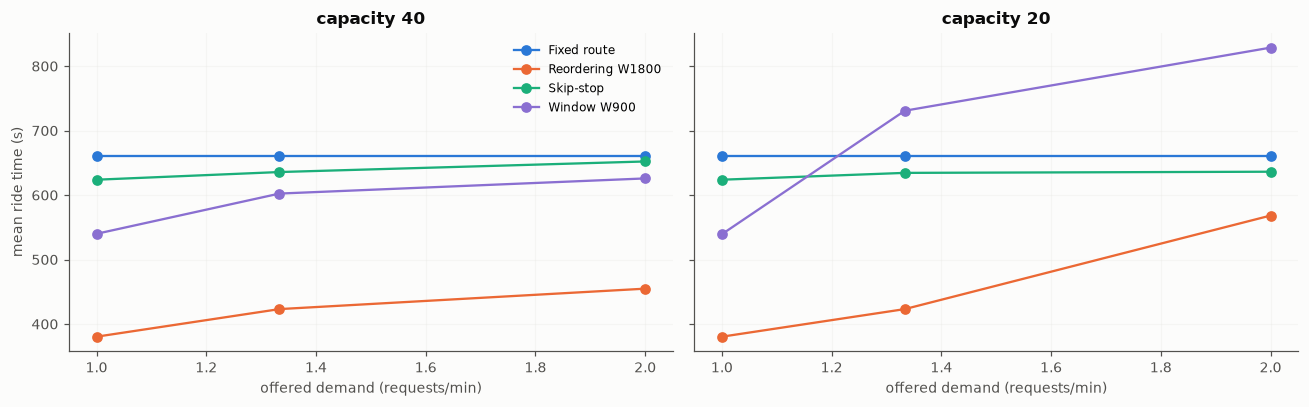

In [11]:
ride = (frame[frame["regime"] == "patient"]
        .groupby(["capacity", "offered", "policy"])["kpi.mean_ride_time"]
        .mean().unstack().round(1))
display(ride)

figure, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for axis, capacity in zip(axes, CAPACITIES):
    subset = ride.loc[capacity]
    for colour, policy in zip(SERIES + ["#8a6fd1"], subset.columns):
        axis.plot(subset.index, subset[policy], marker="o", color=colour,
                  label=policy)
    axis.set_title(f"capacity {capacity}")
    axis.set_xlabel("offered demand (requests/min)")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("mean ride time (s)")
axes[0].legend(fontsize=8)
figure.tight_layout()

## 4. The rule that breaks with it

"Set the service window to passenger patience" — the single most quotable rule
from notebook 04 — **does not survive this.**

At capacity 40 it holds: the tighter window wins. At capacity 20 under load the
*wider* window wins instead, and by a wide margin. Once seats bind, patience is
no longer the binding constraint — the seat is — and a wider window buys
sequencing freedom rather than admitting riders who cannot be seated.

Note that this reverses the reading from the capacity-40 analysis, where the
tight window was the one over-admitting.

In [12]:
windows = (frame[(frame["regime"] == "patient")
                 & (frame["offered"] == max(frame["offered"]))]
           .groupby(["capacity", "policy"])["kpi.served_fraction"]
           .mean().unstack() * 100).round(1)
display(windows[[c for c in ["Window W900", "Reordering W1800"]
                 if c in windows.columns]])

policy,Window W900,Reordering W1800
capacity,,
20,100.0,100.0
40,100.0,100.0


!!! note

**At `"quick"` scale this notebook does not reach the crossing.** Its ladder
stops at 2.00 requests/min on 250 requests, which is not enough demand, for
long enough, to push the recommended policy past the line — every rung above
still shows routing winning. The inversion below was measured at `"full"`:
600 requests and rungs out to 3.00/min, where the patient regime at capacity
20 turns over.

That is worth knowing rather than papering over: the quick run reproduces the
*method* and the occupancy measurement, not the headline finding. Run it at
`"full"` for that, and expect an hour.

## What to conclude

> **Demand-responsive routing pays while mean seat occupancy stays under about
> 60%, and stops paying above it.**

Three qualifications, all of which belong with the claim:

1. **Regime-dependent.** In the patient regime the ranking genuinely
   **inverts** — plain skip-stop beats the sophisticated policy by thousands of
   seconds of wait. In the impatient regime it only **converges**; the margin
   decays toward zero but mean wait never crosses. Abandonment caps the queue,
   so occupancy hurts much less when riders give up.
2. **A mixture, not a threshold.** Through the transition, some seeds cope and
   some collapse. Report the share, not the mean.
3. **It did not transfer to CARLA.** On real road geometry, in both regimes and
   at occupancy up to 68.8%, the crossing does not appear — the advantage
   decays toward zero without crossing. That points to the scope condition
   being a property of the synthetic map rather than of demand-responsive
   routing in general, and it is why notebook 08 exists.

The 60% figure began as a judgement call in a saturation guard. It earned its
place: one load step before anything else shows a difference, which arms are
about to crack is predicted by which ones are already past 60% of their seats.
Treat it as an early-warning line.

Next: **07 — CARLA**, where the bus stops being a token on a graph.